## Lab: RNN with Forecasting

### Wind Turbine Power Prediction with RNN

This lab uses a Recurrent Neural Network to predict wind turbine power output.
* [Data link](https://www.kaggle.com/code/ahmedfathygwely/wind-turbine-dataset-machine-learning-rnn-times/input)

### Step 0: Load libraries & Data

In [2]:
# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the data
df = pd.read_csv('T1.csv')

In [3]:
# Display basic information
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
df.head()

Shape: (50530, 5)

Date/Time                         object
LV ActivePower (kW)              float64
Wind Speed (m/s)                 float64
Theoretical_Power_Curve (KWh)    float64
Wind Direction (°)               float64
dtype: object



,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


### Step 1: Prepare the data

In [5]:
# Step 1: Prepare the data
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M')

print(df['Date/Time'].diff().value_counts().head())
print()

print(df.isnull().sum())
print()

df.describe()

Date/Time
0 days 00:10:00    50497
0 days 00:20:00       11
0 days 00:40:00        2
0 days 03:00:00        1
4 days 08:20:00        1
Name: count, dtype: int64

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64



,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530,50530.000000,50530.000000,50530.000000,50530.000000
mean,2018-07-01 20:01:30.065307648,1307.684332,7.557952,1492.175463,123.687559
min,2018-01-01 00:00:00,-2.471405,0.000000,0.000000,0.000000
25%,2018-04-03 05:22:30,50.677890,4.201395,161.328167,49.315437
50%,2018-06-30 16:15:00,825.838074,7.104594,1063.776283,73.712978
75%,2018-09-26 18:57:30,2482.507568,10.300020,2964.972462,201.696720
max,2018-12-31 23:50:00,3618.732910,25.206011,3600.000000,359.997589
std,NaN,1312.459242,4.227166,1368.018238,93.443736


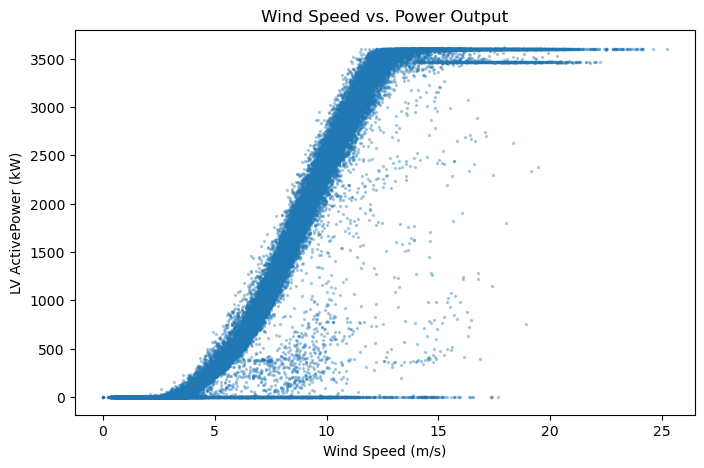

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Wind Speed (m/s)'], df['LV ActivePower (kW)'], s=2, alpha=0.3)
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('LV ActivePower (kW)')
plt.title('Wind Speed vs. Power Output')
plt.show()

In [7]:
features = ['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)']
data = df[features].values

seq_length = 24

n_sequences = len(data) - seq_length
train_size = int(n_sequences * 0.8)

train_rows = train_size + seq_length

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(data[:train_rows])
scaled_data = scaler.transform(data)

print("data shape:", data.shape)
print("train_rows:", train_rows)
print("scaled min per column:", scaled_data.min(axis=0))
print("scaled max per column:", scaled_data.max(axis=0))

data shape: (50530, 3)
train_rows: 40428
scaled min per column: [0. 0. 0.]
scaled max per column: [1. 1. 1.]


### Step 2: Create sequences

In [10]:
# Step 2: Create sequences
def create_sequences(dataset, seq_length):
    """
    Slide a window over the data.
    X[i] = rows i .. i+seq_length-1, all features   -> shape (seq_length, n_features)
    y[i] = row  i+seq_length, column 0 only (power)  -> a single number
    """
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i : i + seq_length])
        y.append(dataset[i + seq_length, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data, seq_length)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("X[0] last row == scaled_data[23]:", np.allclose(X[0][-1], scaled_data[23]))
print("y[0] == scaled_data[24, 0]:      ", np.isclose(y[0], scaled_data[24, 0]))


X shape: (50506, 24, 3)
y shape: (50506,)
X[0] last row == scaled_data[23]: True
y[0] == scaled_data[24, 0]:       True


### Step 3: Split the data

In [11]:
# Step 3: Split the data
train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)

print("train_size matches scaler boundary:", train_size == int((len(data) - seq_length) * 0.8))

dates = df['Date/Time'].values
print("Train targets:", dates[seq_length], "->", dates[seq_length + train_size - 1])
print("Test targets: ", dates[seq_length + train_size], "->", dates[-1])

X_train: (40404, 24, 3)  y_train: (40404,)
X_test:  (10102, 24, 3)  y_test:  (10102,)
train_size matches scaler boundary: True
Train targets: 2018-01-01T04:00:00.000000000 -> 2018-10-18T23:10:00.000000000
Test targets:  2018-10-18T23:20:00.000000000 -> 2018-12-31T23:50:00.000000000


### Step 4: Build the RNN Model

In [12]:
# Step 4: Build the RNN Model
model = Sequential([
    tf.keras.Input(shape=(seq_length, X_train.shape[2])),   # (24, 3)
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()


E0000 00:00:1792533489.706938    1533 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792533489.707378    2855 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792533489.762848    1533 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Train the model

In [13]:
# Step 5: Train the model
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_wind_model.keras',
    monitor='val_loss',
    save_best_only=True
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 0.0160 - val_loss: 0.0079
Epoch 2/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0089 - val_loss: 0.0046
Epoch 3/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0075 - val_loss: 0.0044
Epoch 4/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0071 - val_loss: 0.0043
Epoch 5/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0067 - val_loss: 0.0043
Epoch 6/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0065 - val_loss: 0.0042
Epoch 7/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0064 - val_loss: 0.0042
Epoch 8/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0063 - val_loss: 0.0042
Epoch 9/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0062 - val_loss: 0.0042
Epoch 10/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0061 - val_loss: 0.0044
Epoch 11/50
506/506 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0061 - val_loss: 0.0041
Epoch 12/50
506/506 ━━━━━━━━━━━━━━━━━━━━

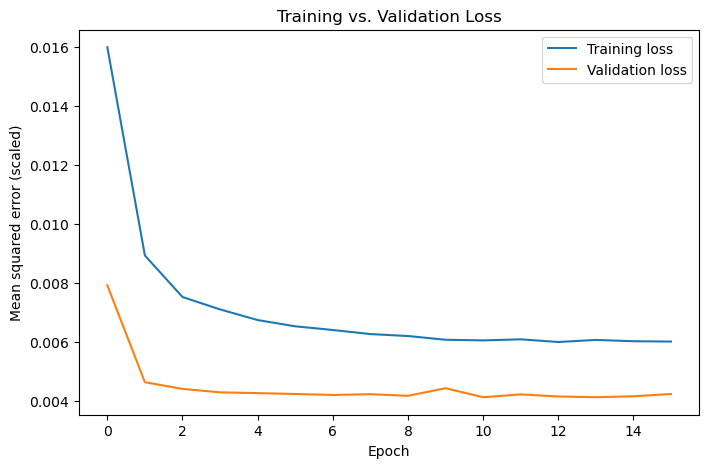

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error (scaled)')
plt.title('Training vs. Validation Loss')
plt.legend()
plt.show()

### Step 6: Evaluate on the test data and visualize the results

In [15]:
# Step 6: Evaluate and visualize
y_pred = model.predict(X_test)

def inverse_power(values):
    placeholder = np.zeros((len(values), 3))
    placeholder[:, 0] = np.ravel(values)
    return scaler.inverse_transform(placeholder)[:, 0]

y_pred_inv = inverse_power(y_pred)
y_test_inv = inverse_power(y_test)

mse  = mean_squared_error(y_test_inv, y_pred_inv)
rmse = math.sqrt(mse)
r2   = r2_score(y_test_inv, y_pred_inv)
print(f"LSTM     -> MSE: {mse:,.0f}  RMSE: {rmse:,.1f} kW  R²: {r2:.4f}")

baseline_inv = inverse_power(X_test[:, -1, 0])
b_rmse = math.sqrt(mean_squared_error(y_test_inv, baseline_inv))
b_r2   = r2_score(y_test_inv, baseline_inv)
print(f"Baseline -> RMSE: {b_rmse:,.1f} kW  R²: {b_r2:.4f}")

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
LSTM     -> MSE: 52,206  RMSE: 228.5 kW  R²: 0.9710
Baseline -> RMSE: 228.4 kW  R²: 0.9710


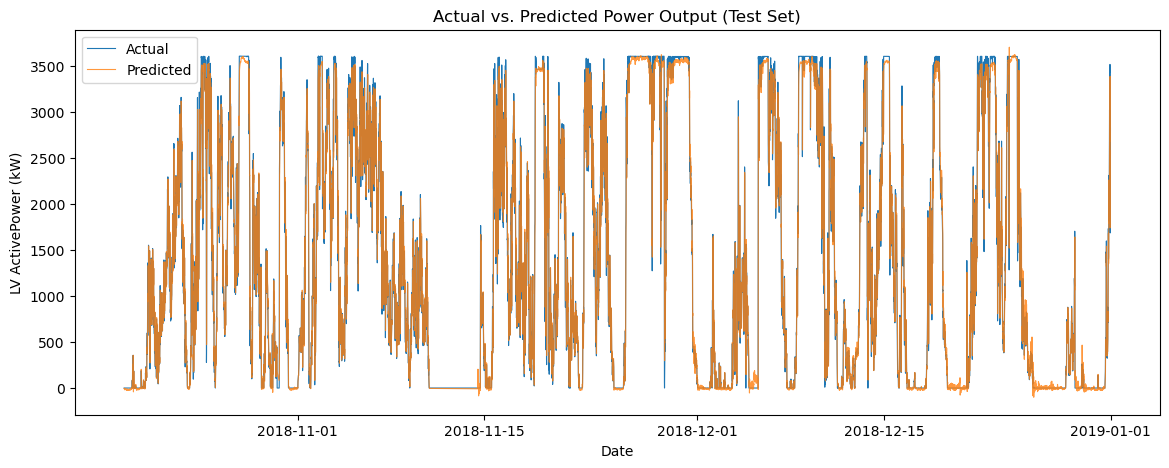

In [16]:
test_dates = df['Date/Time'].values[seq_length + train_size:]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test_inv, label='Actual', linewidth=0.8)
plt.plot(test_dates, y_pred_inv, label='Predicted', linewidth=0.8, alpha=0.8)
plt.xlabel('Date')
plt.ylabel('LV ActivePower (kW)')
plt.title('Actual vs. Predicted Power Output (Test Set)')
plt.legend()
plt.show()

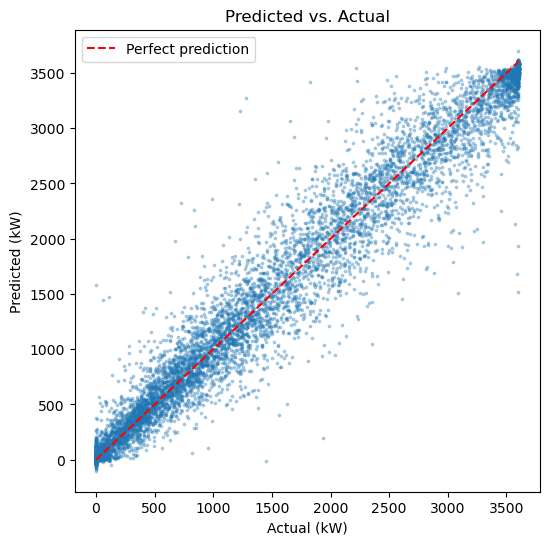

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_inv, y_pred_inv, s=3, alpha=0.3)
lims = [y_test_inv.min(), y_test_inv.max()]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual (kW)')
plt.ylabel('Predicted (kW)')
plt.title('Predicted vs. Actual')
plt.legend()
plt.show()

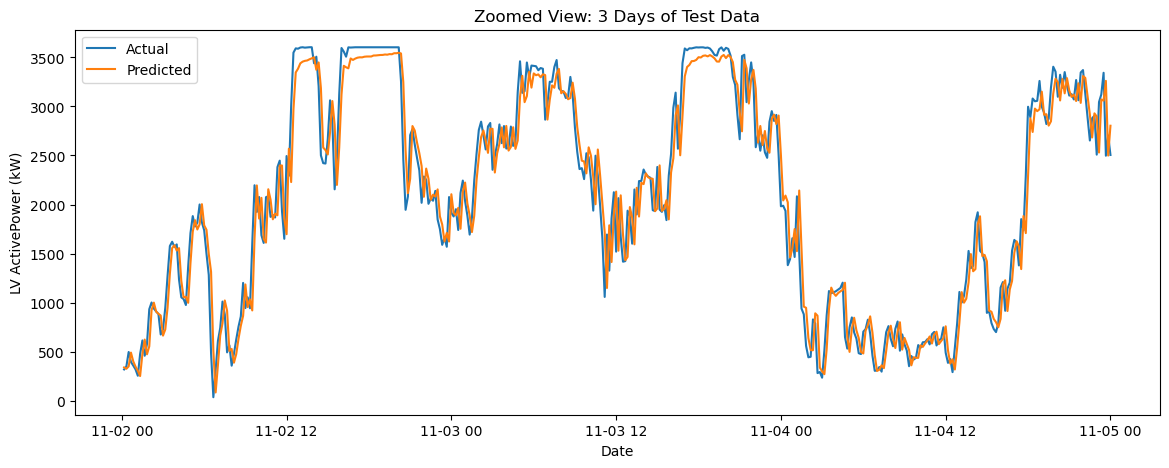

In [18]:
start, window = 2000, 432

plt.figure(figsize=(14, 5))
plt.plot(test_dates[start:start+window], y_test_inv[start:start+window], label='Actual')
plt.plot(test_dates[start:start+window], y_pred_inv[start:start+window], label='Predicted')
plt.xlabel('Date')
plt.ylabel('LV ActivePower (kW)')
plt.title('Zoomed View: 3 Days of Test Data')
plt.legend()
plt.show()